# 03 · Análisis de errores del clasificador cruzado con el EDA
**Rol:** Data Engineer / Analyst · **Sprint 2** · **Seguimiento:** QA-S2-02 (cruzar errores por clase con el EDA)

**Pregunta:** ¿dónde se equivoca el modelo y por qué? El notebook 02 eligió la Regresión Logística y reportó que los errores se concentran en `DERMASON` ↔ `SIRA`. Aquí se cuantifica con los datos del EDA (notebook 01).

| Fase CRISP-DM | Qué se hace aquí |
|---|---|
| 5. Evaluación | Métricas por clase, matriz normalizada y análisis de errores |

**Insumos:** `outputs/reports/predicciones_drybean.csv` (predicciones de la Regresión Logística sobre `test`) y `data/processed/` (datos limpios). La lógica vive en `src/error_analysis.py`, probada en `tests/test_error_analysis.py`.

In [1]:
import os
import platform
from pathlib import Path

# El notebook vive en notebooks/; las rutas del proyecto son relativas a la raíz
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.metrics import confusion_matrix

from src.error_analysis import (confusion_pairs, error_group_summary,
                                per_class_metrics, share_closer_to_other)
from src.models import build_random_forest, load_train_test

REPORTS = Path("outputs/reports")
REPORTS.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

# Trazabilidad TDSP: versiones con las que se obtuvieron los resultados
print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | "
      f"pandas {pd.__version__} | numpy {np.__version__}")

Python 3.13.14 | scikit-learn 1.9.1 | pandas 3.1.1 | numpy 2.5.4


## 1. Datos de entrada y validación

In [2]:
pred = pd.read_csv(REPORTS / "predicciones_drybean.csv")
clean = pd.read_csv("data/processed/dry_bean_clean.csv")
X_train, X_test, y_train, y_test = load_train_test()

# Las predicciones corresponden exactamente al conjunto de prueba del Sprint 1
assert len(pred) == len(y_test) == 2709
assert (pred["real_class"].values == y_test.values).all()
assert (pred[X_test.columns].values == X_test.values).all()

errores = pred[pred["real_class"] != pred["predicted_class"]]
print(f"Errores: {len(errores)} de {len(pred)} ({len(errores) / len(pred):.1%})")

Errores: 218 de 2709 (8.0%)


## 2. Métricas por clase

,precision,recall,f1,support
BARBUNYA,0.925,0.891,0.908,265
BOMBAY,1.000,1.000,1.000,104
CALI,0.911,0.942,0.926,326
DERMASON,0.927,0.907,0.917,709
HOROZ,0.964,0.944,0.954,372
SEKER,0.932,0.943,0.938,406
SIRA,0.858,0.886,0.872,527
macro avg,0.931,0.930,0.931,2709
weighted avg,0.920,0.920,0.920,2709


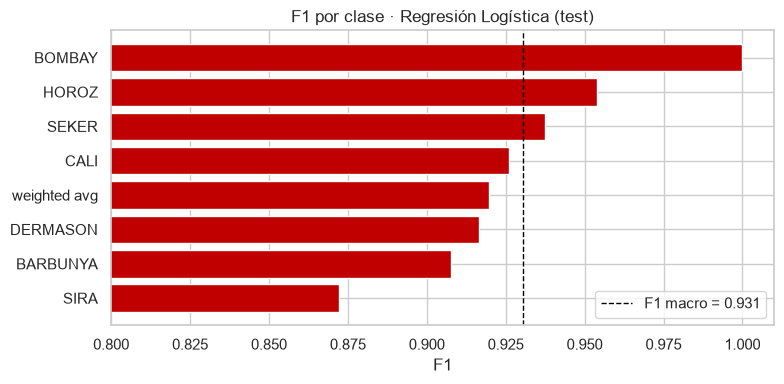

In [3]:
metricas = per_class_metrics(pred["real_class"], pred["predicted_class"])
metricas.round(3).to_csv(REPORTS / "metricas_por_clase_logreg.csv")
display(metricas.round(3))

assert round(metricas.loc["macro avg", "f1"], 4) == 0.9306      # coincide con comparacion_modelos.csv

por_clase = metricas.drop(index="macro avg").sort_values("f1")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(por_clase.index, por_clase["f1"], color="#C00000")
ax.axvline(metricas.loc["macro avg", "f1"], color="black", ls="--", lw=1,
           label=f"F1 macro = {metricas.loc['macro avg', 'f1']:.3f}")
ax.set_xlim(0.8, 1.01); ax.set_xlabel("F1"); ax.set_title("F1 por clase · Regresión Logística (test)")
ax.legend(loc="lower right"); plt.tight_layout()
fig.savefig(REPORTS / "f1_por_clase_logreg.png", dpi=150)
plt.show()

**Lectura:** `BOMBAY` se clasifica sin errores. `SIRA` es la clase más débil (F1 0,872; precisión 0,858) y `BARBUNYA` la que más se escapa (recall 0,891). Como el F1 macro pondera igual a todas las clases, el promedio (0,931) oculta que tres clases (`DERMASON`, `BARBUNYA` y `SIRA`) quedan por debajo de 0,92.

## 3. Matriz de confusión normalizada por fila

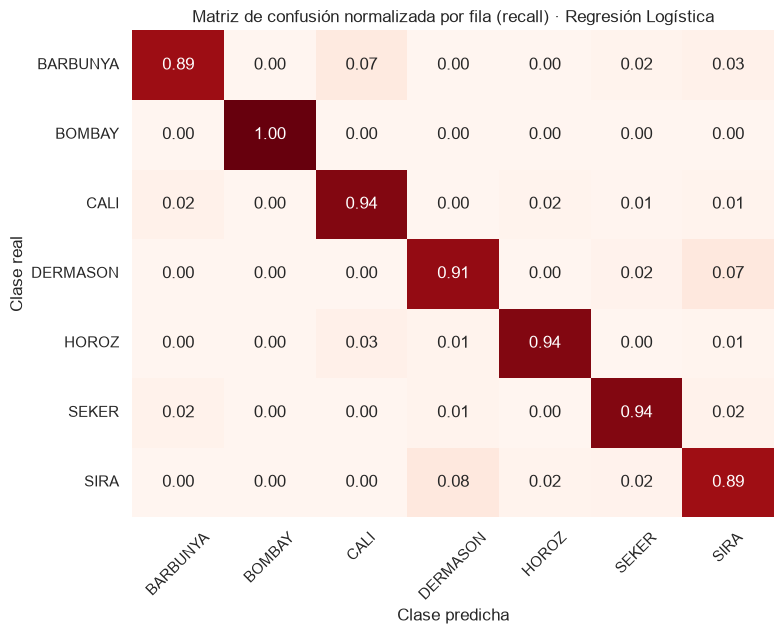

In [4]:
clases = sorted(pred["real_class"].unique())
cm = confusion_matrix(pred["real_class"], pred["predicted_class"], labels=clases, normalize="true")
cm = pd.DataFrame(cm, index=clases, columns=clases)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, cbar=False, ax=ax)
ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
ax.set_title("Matriz de confusión normalizada por fila (recall) · Regresión Logística")
plt.xticks(rotation=45); plt.tight_layout()
fig.savefig(REPORTS / "matriz_confusion_normalizada_logreg.png", dpi=150)
plt.show()

Normalizar por fila muestra qué fracción de cada clase real se pierde, sin que el tamaño de la clase domine la lectura (`BOMBAY` tiene 104 granos de prueba y `DERMASON` 709). La diagonal es el recall de cada clase.

## 4. ¿Dónde se equivoca? Pares de confusión, y si depende del algoritmo

In [5]:
# Mismo Random Forest del notebook 02 (configuración del laboratorio), para comparar los errores
rf = build_random_forest().fit(X_train, y_train)
pred_rf = rf.predict(X_test)

lr_pares = confusion_pairs(pred["real_class"], pred["predicted_class"])
rf_pares = confusion_pairs(pred["real_class"], pred_rf)
comparacion = (lr_pares.merge(rf_pares, on=["real", "predicho"], how="outer",
                              suffixes=("_logreg", "_rf")).fillna(0)
               .astype({"errores_logreg": int, "errores_rf": int}))
comparacion["total"] = comparacion["errores_logreg"] + comparacion["errores_rf"]
comparacion = comparacion.sort_values("total", ascending=False).drop(columns="total").reset_index(drop=True)
comparacion.to_csv(REPORTS / "errores_por_par_logreg_vs_rf.csv", index=False)
display(comparacion.head(8))

n_lr, n_rf = int(lr_pares["errores"].sum()), int(rf_pares["errores"].sum())
print(f"Errores totales -> Regresión Logística: {n_lr} | Random Forest: {n_rf}")

def pareja(df, a, b):
    return int(df[((df.real == a) & (df.predicho == b)) | ((df.real == b) & (df.predicho == a))]["errores"].sum())

d_s_lr, d_s_rf = pareja(lr_pares, "DERMASON", "SIRA"), pareja(rf_pares, "DERMASON", "SIRA")
print(f"DERMASON <-> SIRA: {d_s_lr} errores ({d_s_lr / n_lr:.0%}) con Regresión Logística, {d_s_rf} con Random Forest")
assert (n_lr, n_rf) == (218, 218) and (d_s_lr, d_s_rf) == (94, 95)

,real,predicho,errores_logreg,errores_rf
0,DERMASON,SIRA,53,47
1,SIRA,DERMASON,41,48
2,BARBUNYA,CALI,18,17
3,DERMASON,SEKER,13,17
4,HOROZ,CALI,11,9
5,CALI,BARBUNYA,8,11
6,SIRA,SEKER,9,10
7,SEKER,SIRA,9,8


Errores totales -> Regresión Logística: 218 | Random Forest: 218
DERMASON <-> SIRA: 94 errores (43%) con Regresión Logística, 95 con Random Forest


**Lectura:** los dos modelos cometen **exactamente el mismo número de errores (218)** y los mismos pares dominan en ambos: `DERMASON` ↔ `SIRA` suma 94 errores con la regresión logística y 95 con Random Forest (43 % del total). Pasar de un modelo lineal a un Random Forest, mucho más flexible, **no reduce** estos errores ni cambia su reparto: el límite está sobre todo en que esas clases se solapan en las variables disponibles. `BARBUNYA` → `CALI` es asimétrico: 18 errores en ese sentido y 8 en el inverso.

## 5. DERMASON ↔ SIRA: es un problema de tamaño, no de forma

In [6]:
features = ["Area", "Perimeter", "AspectRatio", "Roundness", "Solidity"]
resumen = error_group_summary(pred, features, class_a="DERMASON", class_b="SIRA")
display(resumen.round(3))

# Medianas de referencia: todas las filas limpias de cada clase
med = clean.groupby("Class")["Area"].median()
for real, otra in [("DERMASON", "SIRA"), ("SIRA", "DERMASON")]:
    e = pred[(pred.real_class == real) & (pred.predicted_class == otra)]["Area"]
    s = share_closer_to_other(e, med[real], med[otra])
    print(f"{real} -> {otra}: {len(e)} errores; {s:.0%} tienen Area más cercana a la mediana de {otra} "
          f"({med[otra]:,.0f} px²) que a la de {real} ({med[real]:,.0f} px²)")
    assert s > 0.75

,DERMASON bien,DERMASON→SIRA,SIRA→DERMASON,SIRA bien
Area,31413.000,40544.000,37318.000,44807.000
Perimeter,658.184,752.604,723.028,798.353
AspectRatio,1.485,1.542,1.525,1.563
Roundness,0.913,0.897,0.893,0.886
Solidity,0.989,0.989,0.988,0.989


DERMASON -> SIRA: 53 errores; 92% tienen Area más cercana a la mediana de SIRA (44,593 px²) que a la de DERMASON (31,890 px²)
SIRA -> DERMASON: 41 errores; 78% tienen Area más cercana a la mediana de DERMASON (31,890 px²) que a la de SIRA (44,593 px²)


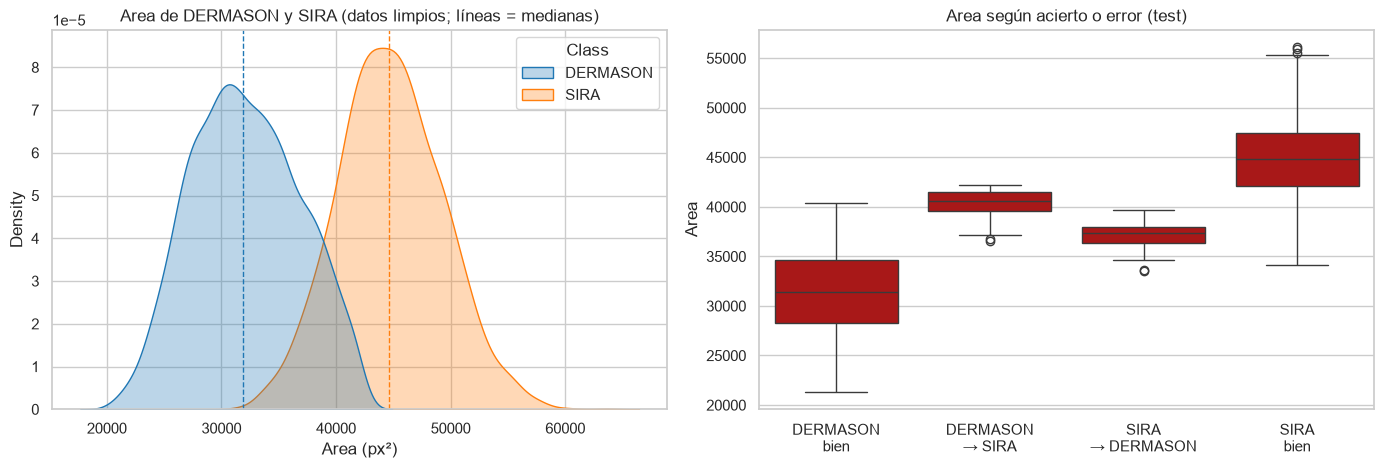

In [7]:
grupo = np.select(
    [(pred.real_class == "DERMASON") & (pred.predicted_class == "DERMASON"),
     (pred.real_class == "DERMASON") & (pred.predicted_class == "SIRA"),
     (pred.real_class == "SIRA") & (pred.predicted_class == "DERMASON"),
     (pred.real_class == "SIRA") & (pred.predicted_class == "SIRA")],
    ["DERMASON\nbien", "DERMASON\n→ SIRA", "SIRA\n→ DERMASON", "SIRA\nbien"], default="otro")
par = pred.assign(grupo=grupo)[lambda d: d["grupo"] != "otro"]
orden = ["DERMASON\nbien", "DERMASON\n→ SIRA", "SIRA\n→ DERMASON", "SIRA\nbien"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colores = {"DERMASON": "tab:blue", "SIRA": "tab:orange"}     # mismo color en curva y mediana
sns.kdeplot(data=clean[clean.Class.isin(colores)], x="Area", hue="Class", hue_order=list(colores),
            palette=colores, common_norm=False, fill=True, alpha=0.3, ax=axes[0])
for c, color in colores.items():
    axes[0].axvline(med[c], color=color, ls="--", lw=1)
axes[0].set_title("Area de DERMASON y SIRA (datos limpios; líneas = medianas)")
axes[0].set_xlabel("Area (px²)")
sns.boxplot(data=par, x="grupo", y="Area", order=orden, color="#C00000", ax=axes[1])
axes[1].set_title("Area según acierto o error (test)"); axes[1].set_xlabel("")
plt.tight_layout()
fig.savefig(REPORTS / "errores_dermason_sira_area.png", dpi=150)
plt.show()

**Lectura:** `AspectRatio` y `Solidity` casi no cambian entre los cuatro grupos, así que la forma no separa a estas dos clases. El `Area` sí: los `DERMASON` mal clasificados son granos más grandes de lo normal (mediana 40.544 px² frente a 31.413 de los acertados) y los `SIRA` mal clasificados son más pequeños de lo normal (37.318 frente a 44.807). El 92 % de los primeros y el 78 % de los segundos tienen un `Area` más cercana a la mediana de la clase equivocada: el modelo se equivoca en los granos que se parecen en tamaño a la otra variedad.

## 6. ¿Cada par de confusión se explica por la misma variable?

In [8]:
etiquetas = {"Area": "tamaño", "AspectRatio": "alargamiento", "Roundness": "redondez"}
filas = []
for _, r in lr_pares.head(6).iterrows():
    e = pred[(pred.real_class == r["real"]) & (pred.predicted_class == r["predicho"])]
    cercanias = {f: share_closer_to_other(e[f], clean[clean.Class == r["real"]][f].median(),
                                          clean[clean.Class == r["predicho"]][f].median())
                 for f in etiquetas}
    mejor = max(cercanias, key=cercanias.get)
    filas.append({"real → predicho": f"{r['real']} → {r['predicho']}", "errores": r["errores"],
                  **{f"{etiquetas[f]} ({f})": round(v, 2) for f, v in cercanias.items()},
                  "variable que lo explica": etiquetas[mejor] if cercanias[mejor] >= 0.75 else "ninguna aislada"})
tabla = pd.DataFrame(filas)
tabla.to_csv(REPORTS / "errores_por_par_y_variable.csv", index=False)
display(tabla)

# Controles de las cifras citadas en el texto
t = tabla.set_index("real → predicho")["variable que lo explica"]
assert t["DERMASON → SIRA"] == t["SIRA → DERMASON"] == t["DERMASON → SEKER"] == "tamaño"
assert t["BARBUNYA → CALI"] == "redondez" and t["HOROZ → CALI"] == "alargamiento"
assert t["SEKER → BARBUNYA"] == "ninguna aislada"

,real → predicho,errores,tamaño (Area),alargamiento (AspectRatio),redondez (Roundness),variable que lo explica
0,DERMASON → SIRA,53,0.92,0.60,0.55,tamaño
1,SIRA → DERMASON,41,0.78,0.49,0.41,tamaño
2,BARBUNYA → CALI,18,0.44,0.44,0.94,redondez
3,DERMASON → SEKER,13,0.92,0.69,0.62,tamaño
4,HOROZ → CALI,11,0.36,0.91,0.45,alargamiento
5,SEKER → BARBUNYA,9,0.33,0.33,0.67,ninguna aislada


Cada celda es la proporción de errores de ese par cuya variable queda más cerca de la mediana de la clase equivocada que de la propia (≥ 0,75 se considera que la variable lo explica; 0,50 sería azar). Es un indicador descriptivo, no una prueba causal.

**Lectura:** la causa cambia según el par.
- **Tamaño:** `DERMASON` → `SIRA`, `SIRA` → `DERMASON` y `DERMASON` → `SEKER` (≥ 78 %).
- **Redondez:** `BARBUNYA` → `CALI` (94 %). Aquí el tamaño **no** ayuda (44 %; las áreas medianas son casi iguales, 69.582 frente a 74.792 px²).
- **Alargamiento:** `HOROZ` → `CALI` (91 %).
- `SEKER` → `BARBUNYA` no se explica por una sola variable.

## 7. Conclusiones y recomendaciones

**Hallazgos**
1. El modelo comete **218 errores en 2.709 granos (8,0 %)** y Random Forest comete exactamente los mismos 218, con los mismos pares dominantes. El límite viene sobre todo del **solapamiento entre clases**: pasar de un modelo lineal a un Random Forest no cambia ni el número de errores ni su reparto.
2. **`DERMASON` ↔ `SIRA` concentra el 43 % de los errores** y se explica por tamaño: la forma es casi idéntica. Es también la causa de que `SIRA` tenga el peor F1 (0,872).
3. **Cada par tiene su propia variable** (tamaño, redondez o alargamiento), lo que sugiere que un modelo capaz de combinarlas de forma no lineal tiene margen donde uno lineal no.
4. `BOMBAY` es perfecta y `BARBUNYA` pierde el 11 % de sus granos (recall 0,891), sobre todo hacia `CALI`.

**Recomendaciones**
- **ML Engineer:** no invertir más en hiperparámetros de Regresión Logística o Random Forest. Probar modelos de frontera no lineal (SVM RBF, boosting) con el mismo protocolo de validación cruzada y comparar por clase, no solo con F1 macro. La exploración preliminar de la bitácora 06 sugiere una ganancia pequeña (≈ +0,6 puntos de F1 macro en validación cruzada), a confirmar.
- **Product Owner:** decidir si `SIRA` y `BARBUNYA` necesitan un umbral propio (por ejemplo, recall mínimo por clase) y si los granos del solapamiento `DERMASON`–`SIRA` pueden derivarse a revisión manual.
- **Puesta en producción (inferencia a validar):** como el tamaño en píxeles es lo que separa a la pareja más difícil, un cambio de cámara, distancia o resolución degradaría justo esa pareja. Conviene fijar y documentar las condiciones de captura.

**Limitaciones.** Un único split 80/20 (con 41 y 53 errores por sentido las proporciones son inestables); el indicador de cercanía a la mediana es descriptivo; las predicciones de la Regresión Logística vienen del CSV del Sprint 2 y las de Random Forest se recalculan aquí con la configuración del laboratorio.